# 한국어 설정과 조직 범주화 실험 검토

실제 실행이 완료된 집계 JSON을 읽습니다. 기존 테스트 재평가와 가상 조직 실험을 구분하며, 실제 고객 문서는 포함하지 않습니다.

## 결과 파일 확인
두 실험이 완료되었는지 확인하고 실행 식별자를 표시합니다. 저장소 루트 또는 `research/`에서 실행하세요.

In [1]:
import json
from pathlib import Path
root = Path.cwd()
if not (root / 'research/results').exists():
    root = root.parent
results = root / 'research/results'
e2 = json.loads((results / 'korean-settings.json').read_text())
e3 = json.loads((results / 'organization-utility-risk.json').read_text())
assert e2['complete'] and e3['complete']
print('E2:', e2['manifest']['run_id'])
print('E3:', e3['manifest']['run_id'])

E2: 7501ceeb38bf8a02af73ddbbdee58aa13d9b4e2921d3d19f733e884a5cc8279e
E3: dd9fcc8e4b8a9990e52866fcc1de572b0fa1360be81cc30cfecd0708ef11b97b


## 탐지 결과와 정책 비교
표의 F1은 과거 KDPII 테스트의 재평가입니다. 공격 기대 성공률은 정답이 후보 집합에 있을 때 균등 추정하는 공격자의 성공 확률이며, 보장된 익명성이 아닙니다.

In [2]:
from IPython.display import Markdown, display
display(Markdown((results / 'tables.md').read_text()))

| 모델 / 조건 | KDPII Exact F1 (그룹 95% 구간) | 이름 재현율 | 문자 재현율 | 음성 문서 오탐 |
|---|---:|---:|---:|---:|
| nvidia / baseline | 8.71% (7.11%–10.16%) | 12.99% | 88.60% | 559 / 580 |
| nvidia / threshold_only | 12.95% (10.48%–15.40%) | 5.93% | 59.11% | 308 / 580 |
| nvidia / labels_threshold | 14.85% (12.06%–17.45%) | 20.06% | 60.53% | 206 / 580 |
| nvidia / boundary_threshold | 37.52% (33.56%–41.64%) | 11.02% | 54.95% | 388 / 580 |
| nvidia / joint | 34.44% (31.07%–38.02%) | 13.56% | 49.95% | 354 / 580 |
| fastino / baseline | 19.45% (16.66%–22.25%) | 18.08% | 81.31% | 182 / 580 |
| fastino / threshold_only | 23.91% (20.57%–27.30%) | 10.17% | 62.06% | 128 / 580 |
| fastino / labels_threshold | 25.18% (21.82%–28.60%) | 16.67% | 55.69% | 106 / 580 |
| fastino / boundary_threshold | 48.93% (44.77%–52.66%) | 6.21% | 71.62% | 182 / 580 |
| fastino / joint | 48.93% (44.77%–52.66%) | 6.21% | 71.62% | 182 / 580 |
| roberta / reference | 91.65% (90.03%–93.33%) | 95.48% | 99.21% | 0 / 580 |

| 구간 조건 / 정책 | 팀 검색 Recall@5 | 팀 검색 MRR | 명부 공격 기대 성공률 | 명부+직급·과제 공격 기대 성공률 |
|---|---:|---:|---:|---:|
| gold / raw | 15.42% | 19.17% | 98.33% | 100.00% |
| gold / mask | 16.73% | 21.45% | 0.83% | 26.39% |
| gold / pseudonym | 16.73% | 21.45% | 0.83% | 26.39% |
| gold / team | 81.30% | 87.64% | 11.19% | 73.21% |
| gold / division | 19.20% | 21.95% | 2.87% | 59.88% |
| gold / center | 15.30% | 20.12% | 1.49% | 41.45% |
| roberta / raw | 15.42% | 19.17% | 98.33% | 100.00% |
| roberta / mask | 15.99% | 22.02% | 0.83% | 8.76% |
| roberta / pseudonym | 15.99% | 22.03% | 0.83% | 8.76% |
| roberta / team | 80.45% | 87.30% | 11.19% | 49.01% |
| roberta / division | 17.11% | 21.82% | 2.87% | 24.76% |
| roberta / center | 14.19% | 20.64% | 1.49% | 14.12% |


## 시각화
오차 막대는 세 가상 세계의 최솟값–최댓값입니다. 모집단 신뢰구간이나 운영 검색 성능을 나타내지 않습니다.

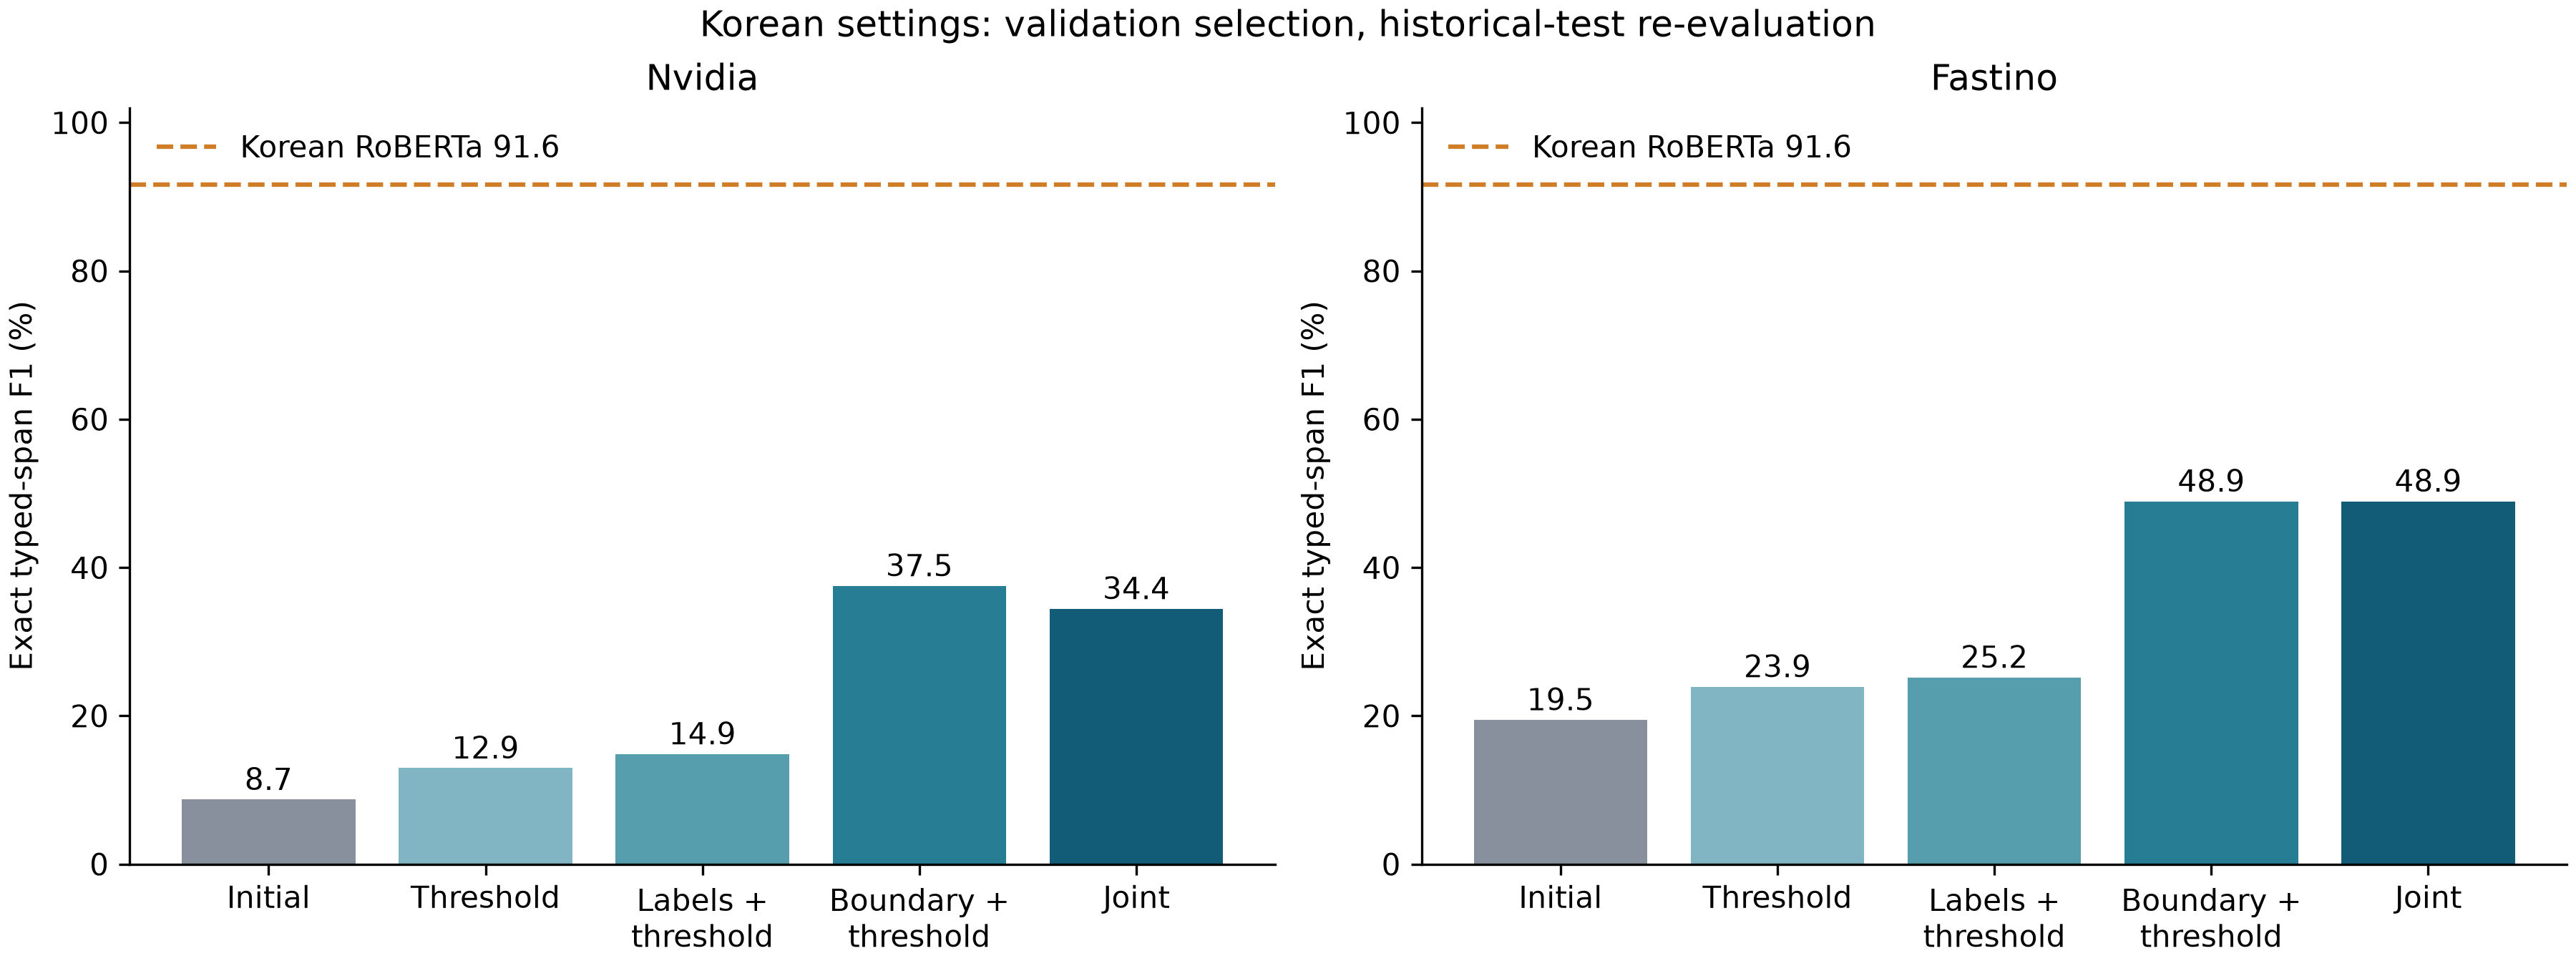

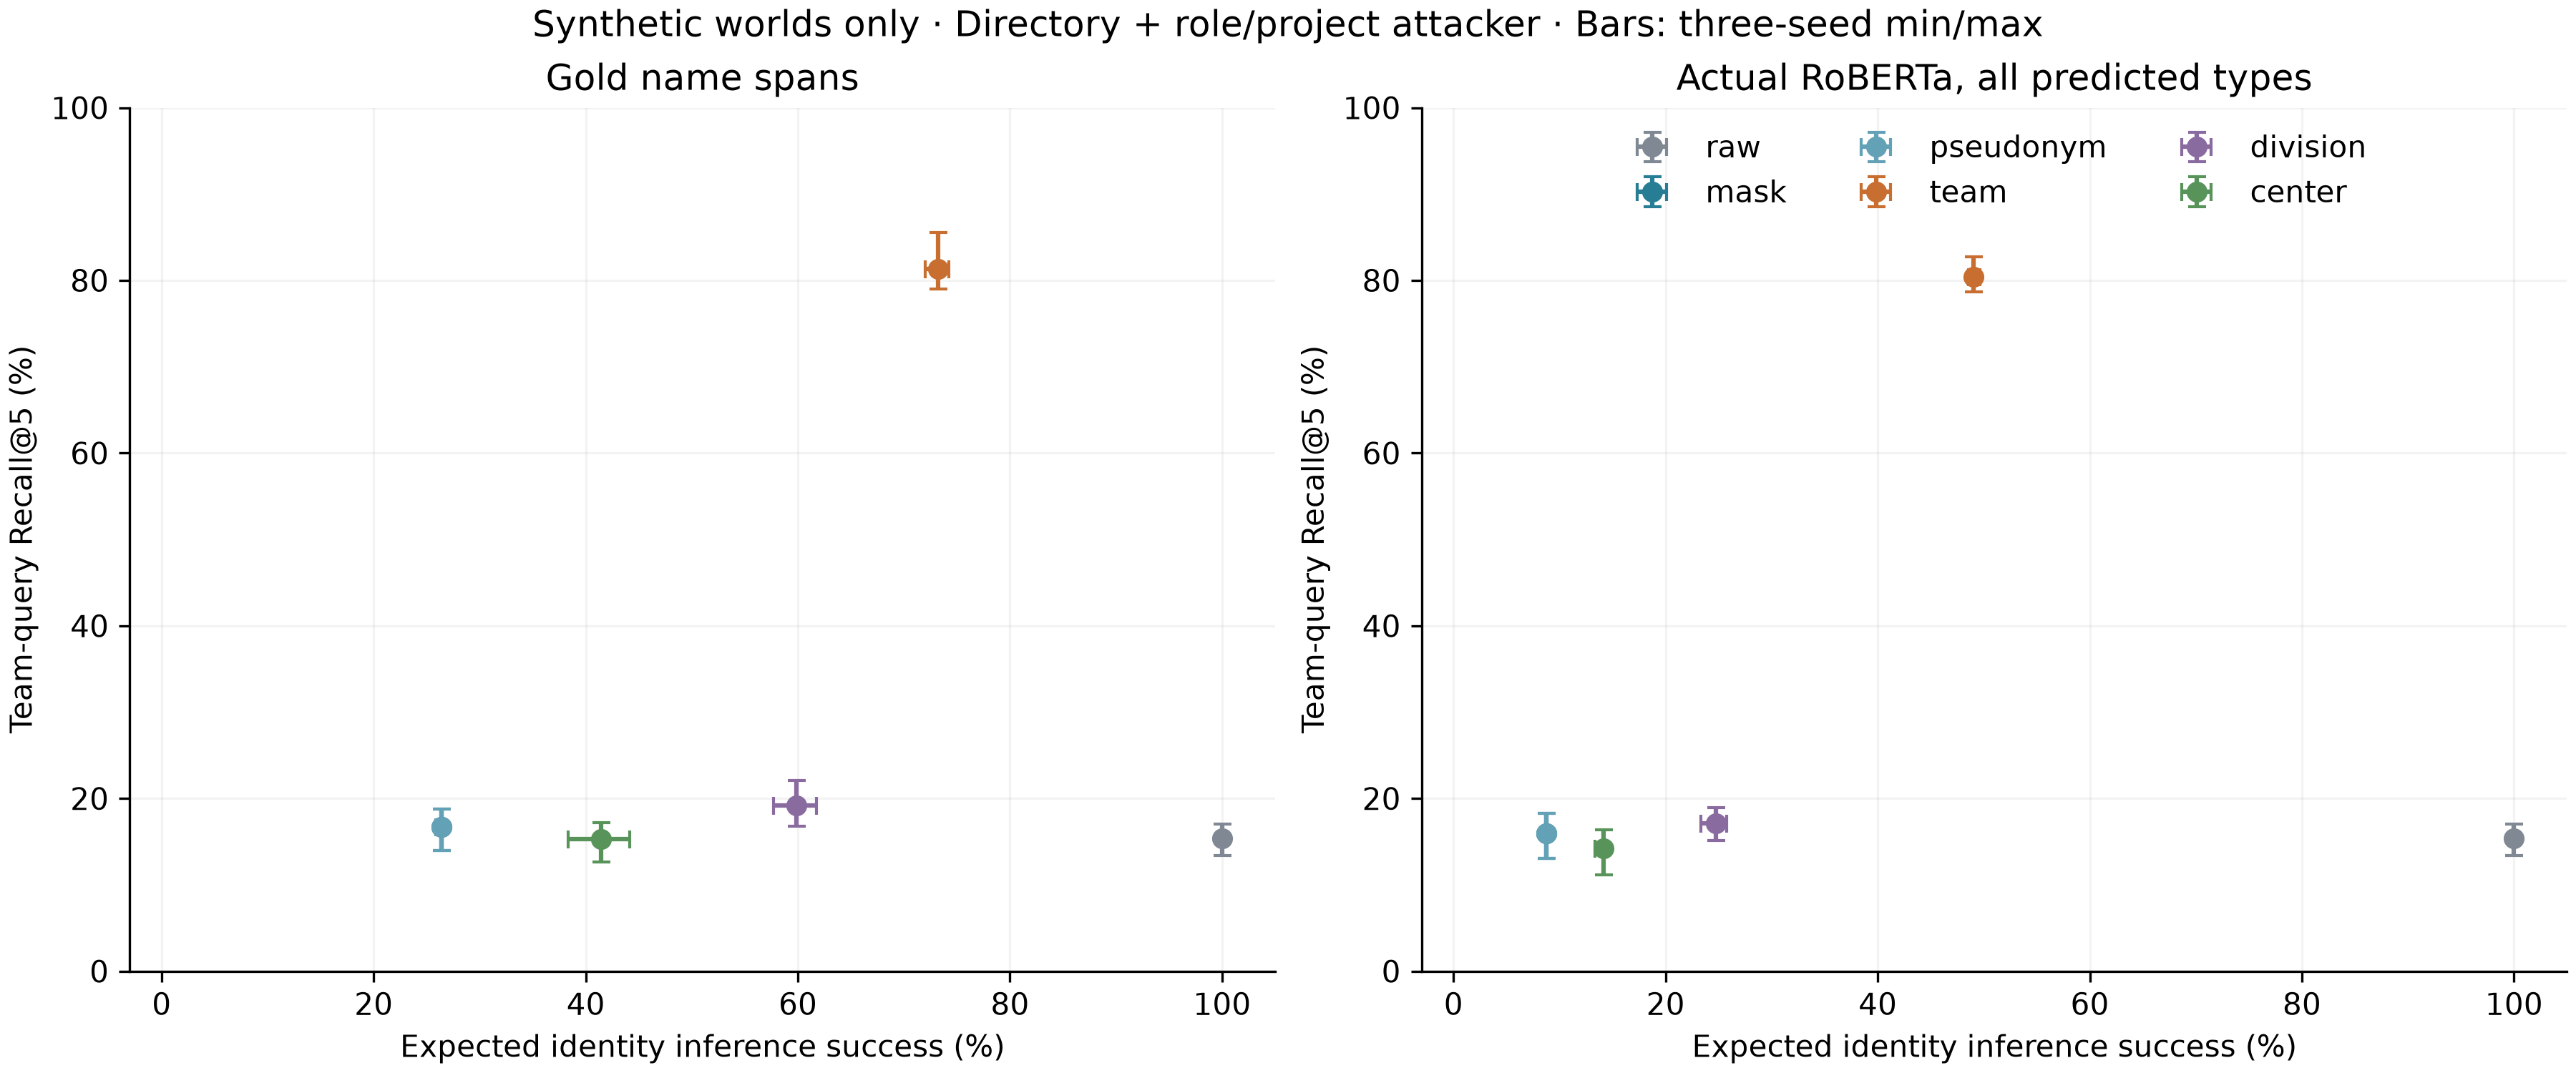

In [3]:
from IPython.display import Image
display(Image(filename=str(results / 'figures/korean-settings.png')))
display(Image(filename=str(results / 'figures/utility-risk.png')))

## 실제 탐지의 추가 치환
이름 외 직급·소속·업무참조 문자열도 탐지되었습니다. 실제 NER 조건의 위험 감소와 검색 손실을 이름 탐지 정확도만의 효과로 해석하면 안 됩니다.

In [4]:
print(json.loads((results / 'organization-predicted-label-counts.json').read_text()))
for w in e3['worlds']:
    print(w['seed'], 'name F1:', w['detection']['exact']['f1'], 'queries:', w['query_counts'])

{'PERSON_NAME': 720, 'POSITION': 609, 'PASSPORT_NUM': 637, 'AFFILIATION': 112}
20260921 name F1: 1.0 queries: {'team': 96, 'division': 32, 'center': 16, 'topic_control': 8}
20260922 name F1: 1.0 queries: {'team': 94, 'division': 32, 'center': 16, 'topic_control': 8}
20260923 name F1: 1.0 queries: {'team': 95, 'division': 32, 'center': 16, 'topic_control': 8}
